# Simons demo

Forecasts with [Simons-25M](https://huggingface.co/abel-lab/Simons-25M) on synthetic hourly data,
top to bottom on a CPU in under a minute (after a 100 MB download of the weights).

Setup: load the model on the GPU when there is one (or swap in `abel-lab/Simons-60M`, `-178M` or
`-297M`).

In [1]:
# pip install "git+https://github.com/Abel-ai-lab/Simons" matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch

from simons import QUANTILES, Simons, forecast_series

device = "cuda" if torch.cuda.is_available() else "cpu"
model = Simons.from_pretrained("abel-lab/Simons-25M", device=device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters on {device}")

25.1M parameters on cpu


Synthetic hourly series: a level, a daily cycle and noise.

In [2]:
rng = np.random.default_rng(0)
H = 48  # forecast horizon: two days


def hourly(length, level=10.0, amplitude=3.0):
    t = np.arange(length)
    return level + amplitude * np.sin(2 * np.pi * t / 24) + rng.normal(0, 0.5, length)

One series: a `[1, time]` history gives `[1, horizon, 9]` quantiles.

In [3]:
series = hourly(24 * 21 + H)
history, future = series[:-H], series[-H:]
quantiles = model.forecast(history[None], horizon=H)
quantiles.shape

torch.Size([1, 48, 9])

A batch: the rows of a `[batch, time]` history are forecast independently, in one call.

In [4]:
batch = np.stack([hourly(24 * 21, level, amplitude)
                  for level, amplitude in ((5, 1), (10, 3), (20, 2), (40, 8))])
model.forecast(batch, horizon=H).shape

torch.Size([4, 48, 9])

The 9 quantiles are the levels 0.1, ..., 0.9: level 0.5 is the median, and levels 0.1 and 0.9 bound
an 80% prediction interval.

In [5]:
q = quantiles[0].cpu().numpy()  # [horizon, 9]
median, low, high = q[:, QUANTILES.index(0.5)], q[:, 0], q[:, -1]
print("quantile levels:", QUANTILES)
for step in (0, 11, 23, 47):
    print(f"hour {step + 1:2d}: median {median[step]:5.2f}, 80% interval "
          f"[{low[step]:5.2f}, {high[step]:5.2f}], actual {future[step]:5.2f}")
print(f"actual values inside the 80% interval: {np.mean((low <= future) & (future <= high)):.0%}")

quantile levels: (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)
hour  1: median 10.09, 80% interval [ 9.42, 10.76], actual 10.62
hour 12: median 10.75, 80% interval [10.11, 11.39], actual 10.29
hour 24: median  9.19, 80% interval [ 8.49,  9.88], actual  9.37
hour 48: median  9.17, 80% interval [ 8.50,  9.83], actual  8.97
actual values inside the 80% interval: 81%


A plot of the last week of history, the median and the 10-90% band.

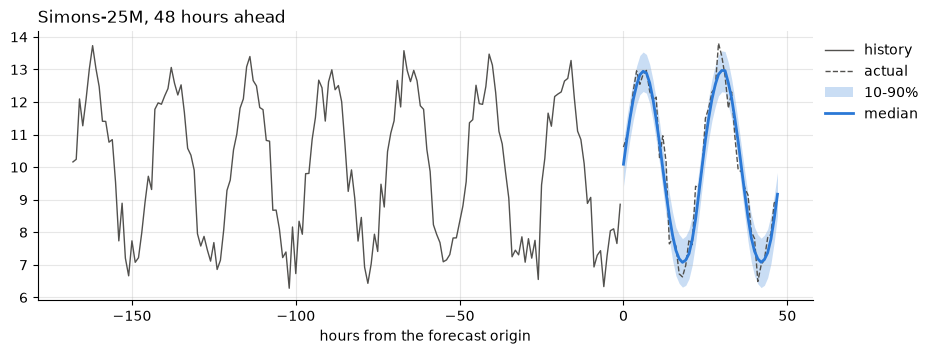

In [6]:
def plot_forecast(ax, history, q, future, title, shown=24 * 7):
    ahead = np.arange(len(q))
    ax.plot(np.arange(-shown, 0), history[-shown:], color="#52514e", lw=1, label="history")
    ax.plot(ahead, future, color="#52514e", lw=1, ls="--", label="actual")
    ax.fill_between(ahead, q[:, 0], q[:, -1], color="#2a78d6", alpha=0.25, lw=0,
                    label="10-90%")
    ax.plot(ahead, q[:, 4], color="#2a78d6", lw=2, label="median")
    ax.set_title(title, loc="left")
    ax.set_xlabel("hours from the forecast origin")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)


fig, ax = plt.subplots(figsize=(10, 3.5))
plot_forecast(ax, history, q, future, "Simons-25M, 48 hours ahead")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
plt.show()

A multivariate panel: the variates of a `[batch, variates, time]` row (up to 32) are forecast
jointly.

In [7]:
shared = np.cumsum(rng.normal(0, 0.3, 24 * 21))  # a random walk the three variates share
panel = np.stack([hourly(24 * 21, level) + shared for level in (5, 10, 15)])[None]
model.forecast(panel, horizon=H).shape

torch.Size([1, 3, 48, 9])

`forecast_series` takes a list of `[time]` or `[variates, time]` arrays of any lengths and returns
one numpy array per series.

In [8]:
inputs = [hourly(200), hourly(1_000), hourly(5_000), panel[0]]
for x, out in zip(inputs, forecast_series(model, inputs, horizon=H)):
    print(x.shape, "->", out.shape)

(200,) -> (48, 9)
(1000,) -> (48, 9)
(5000,) -> (48, 9)
(3, 504) -> (3, 48, 9)


Known-future covariates: hourly sales driven by the temperature (numeric) and a promotion calendar
(categorical), both known over the horizon.

In [9]:
T = 24 * 28  # four weeks of history
steps = np.arange(T + H)
temperature = (18 + 6 * np.sin(2 * np.pi * (steps - 9) / 24)
               + np.cumsum(rng.normal(0, 0.3, T + H)))
promo = np.where(np.isin(steps // 24, [3, 4, 10, 15, 16, 17, 22, 28]), "promo", "none")
sales = 40 + 1.5 * temperature + 20 * (promo == "promo") + rng.normal(0, 2, T + H)
history, future = sales[:T], sales[T:]

The same history forecast without and with the covariates; each covariate is one array of history +
horizon values.

In [10]:
plain = forecast_series(model, [history], horizon=H)[0]
informed = forecast_series(model, [history], horizon=H,
                           future_covariates=[{"temperature": temperature, "promo": promo}])[0]
for name, q in (("plain", plain), ("with covariates", informed)):
    print(f"{name:>15}: mean absolute error of the median {np.abs(q[:, 4] - future).mean():.2f}")

          plain: mean absolute error of the median 14.30
with covariates: mean absolute error of the median 1.33


Side by side: with the covariates, the forecast follows the promotion on the first day of the
horizon.

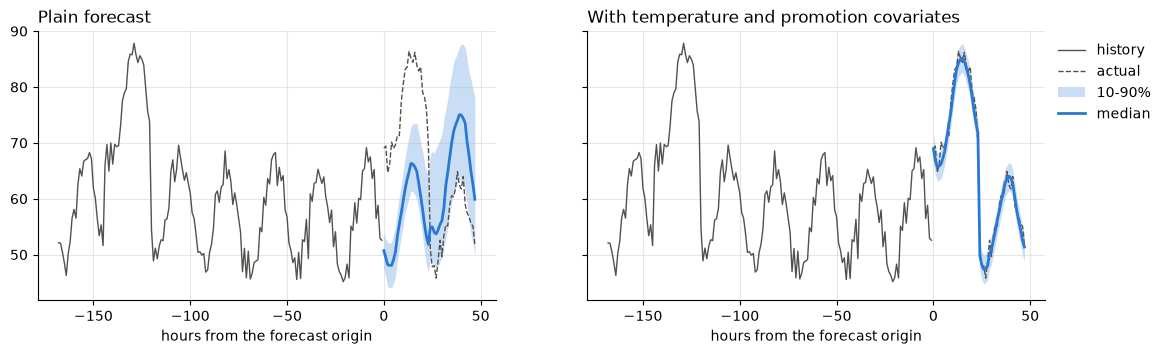

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
plot_forecast(axes[0], history, plain, future, "Plain forecast")
plot_forecast(axes[1], history, informed, future, "With temperature and promotion covariates")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
plt.show()